# A Pre-Training Reference for Feature Importance in Binary Classification

This notebook reproduces the results of the paper. For each dataset it:

1. ranks features by the absolute **standardized mean difference** (SMD, Cohen's $d$) between the two classes,
   computed on the training split only;
2. trains five model families and ranks features by each model's importance;
3. checks whether the SMD's top feature is among each model's top 1 and top 3 features, and compares this with
   what random rankings would give.

**Setup.** `pip install -r requirements.txt`, then run `python prepare_data.py` once to download the ten datasets
into `data/`. Run this notebook top to bottom; results are written to `results/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rbo
import shap
from scipy.stats import spearmanr
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import DMatrix, XGBClassifier

SEEDS = range(5)
MAX_ROWS = 15_000   # larger datasets are subsampled to this many rows
SHAP_ROWS = 80      # test rows explained by SHAP
RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)

## 1. Datasets

Each dataset is a CSV in `data/` with a binary target and its features. Numeric features are used as they are;
categorical features are one-hot encoded for the models.

In [2]:
BC = ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "mean compactness",
      "mean concavity", "mean concave points", "mean symmetry", "mean fractal dimension", "radius error",
      "texture error", "perimeter error", "area error", "smoothness error", "compactness error",
      "concavity error", "concave points error", "symmetry error", "fractal dimension error", "worst radius",
      "worst texture", "worst perimeter", "worst area", "worst smoothness", "worst compactness",
      "worst concavity", "worst concave points", "worst symmetry", "worst fractal dimension"]

# name: (target, numeric features, categorical features)
DATASETS = {
    "titanic": ("survived", ["sibsp", "parch", "fare", "age"], ["sex", "pclass", "embarked"]),
    "diabetes": ("Outcome", ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI",
                             "DiabetesPedigreeFunction", "Age"], []),
    "adult": ("income", ["age", "education_num", "capital_gain", "capital_loss", "hours_per_week"],
              ["sex", "married", "workclass_grp", "occupation_grp", "relationship_grp", "race_grp", "native_us"]),
    "compas": ("two_year_recid", ["age", "priors_count"], ["sex", "race_black", "c_charge_degree", "juv_any"]),
    "breast_cancer": ("target", BC, []),
    "german": ("target", ["duration", "credit_amount", "installment_commitment", "residence_since", "age",
                          "existing_credits", "num_dependents"],
               ["checking_status", "credit_history", "purpose", "savings_status", "employment", "personal_status",
                "other_parties", "property_magnitude", "other_payment_plans", "housing", "job", "own_telephone",
                "foreign_worker"]),
    "bank": ("target", ["age", "balance", "day", "campaign", "pdays", "previous"],
             ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]),
    "heart": ("target", ["age", "resting_blood_pressure", "serum_cholestoral", "maximum_heart_rate_achieved",
                         "oldpeak"],
              ["sex", "chest", "fasting_blood_sugar", "resting_electrocardiographic_results",
               "exercise_induced_angina", "slope", "number_of_major_vessels", "thal"]),
    "student": ("target", ["age", "absences", "failures", "studytime", "goout", "Dalc", "Walc", "health", "Medu",
                           "Fedu", "traveltime", "famrel", "freetime"],
                ["school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob", "reason", "guardian",
                 "schoolsup", "famsup", "paid", "activities", "nursery", "higher", "internet", "romantic"]),
    "taiwan": ("target", ["LIMIT_BAL", "AGE"] + [f"PAY_{i}" for i in range(1, 7)]
               + [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)],
               ["SEX", "EDUCATION", "MARRIAGE"]),
}

data = {name: pd.read_csv(f"data/{name}.csv") for name in DATASETS}
for name, (target, num, cat) in DATASETS.items():
    print(f"{name:14s} n = {len(data[name]):6d}   p = {len(num) + len(cat)}")

titanic        n =    891   p = 7
diabetes       n =    768   p = 8
adult          n =  45222   p = 12
compas         n =   6172   p = 6
breast_cancer  n =    569   p = 30
german         n =   1000   p = 20
bank           n =  45211   p = 15
heart          n =    270   p = 13
student        n =    649   p = 30
taiwan         n =  30000   p = 23


## 2. The SMD ranking

For feature $j$, $\Delta_j = (\mu_{1j} - \mu_{0j}) \,/\, \sqrt{(s_{1j}^2 + s_{0j}^2)/2}$, and features are ranked by
$|\Delta_j|$. A categorical feature is scored by the largest $|\Delta|$ over its category levels, treating each
level as a 0/1 indicator. The class mean of an indicator is the share $q$ of that class in the level, and its
sample variance is $q(1-q)\,n/(n-1)$, so every level is scored from class counts gathered in one pass.
Scoring all $p$ features therefore takes $O(np)$ time.

In [3]:
def smd(x, y):
    # |SMD| of a numeric column x between the classes y == 1 and y == 0.
    x1, x0 = x[y == 1], x[y == 0]
    pooled_sd = np.sqrt((x1.var() + x0.var()) / 2)
    return 0.0 if pooled_sd == 0 else abs(x1.mean() - x0.mean()) / pooled_sd

def smd_categorical(x, y):
    # Largest |SMD| over the levels of a categorical column x, from class counts per level.
    counts = pd.crosstab(x.astype(str), y)            # rows: levels, columns: class 0 and 1
    n1, n0 = counts[1].sum(), counts[0].sum()
    q1, q0 = counts[1] / n1, counts[0] / n0            # class means of each level's indicator
    var1, var0 = q1 * (1 - q1) * n1 / (n1 - 1), q0 * (1 - q0) * n0 / (n0 - 1)
    pooled_sd = np.sqrt((var1 + var0) / 2)
    return (abs(q1 - q0) / pooled_sd).where(pooled_sd > 0, 0.0).max()

def smd_scores(df, target, num, cat):
    y = df[target].values
    scores = {col: smd(df[col], y) for col in num}
    scores.update({col: smd_categorical(df[col], y) for col in cat})
    return pd.Series(scores)

# Example: Titanic, on the full data
smd_scores(data["titanic"], *DATASETS["titanic"]).sort_values(ascending=False).round(2)

sex         1.29
pclass      0.70
fare        0.50
embarked    0.34
parch       0.17
age         0.13
sibsp       0.08
dtype: float64

## 3. Model importance rankings

All models use the same design matrix. Importances of one-hot columns are summed back to their original feature.

| Ranking | Importance |
|---|---|
| `DT`, `RF` | Gini importance |
| `RF-SHAP`, `XGB-SHAP` | mean \|TreeSHAP\| on 80 test rows |
| `XGB` | gain |
| `LR` | \|coefficient\| on standardized inputs |
| `MLP-SHAP` | mean \|KernelSHAP\| on the same 80 test rows |

`DT`, `RF`, `XGB`, `LR` and `MLP-SHAP` are the five primary rankings (one per model family).

In [4]:
PRIMARY = ["DT", "RF", "XGB", "LR", "MLP-SHAP"]

def design_matrix(df, num, cat):
    # Numeric columns as they are, categorical columns one-hot encoded as "feature=level".
    onehot = [pd.get_dummies(df[c].astype(str), prefix=c, prefix_sep="=").astype(float) for c in cat]
    return pd.concat([df[num]] + onehot, axis=1)

def model_importances(Xtr, ytr, Xte, seed):
    rows = np.random.RandomState(seed).choice(len(Xte), min(SHAP_ROWS, len(Xte)), replace=False)
    imp = {}

    dt = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=seed).fit(Xtr, ytr)
    imp["DT"] = dt.feature_importances_

    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=seed).fit(Xtr, ytr)
    imp["RF"] = rf.feature_importances_
    sv = shap.TreeExplainer(rf).shap_values(Xte.iloc[rows])           # shape (rows, columns, classes)
    imp["RF-SHAP"] = np.abs(sv[..., 1]).mean(axis=0)

    xgb = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                        importance_type="gain", eval_metric="logloss", n_jobs=-1,
                        random_state=seed).fit(Xtr.values, ytr)
    imp["XGB"] = xgb.feature_importances_
    sv = xgb.get_booster().predict(DMatrix(Xte.values[rows]), pred_contribs=True)[:, :-1]  # last column = bias
    imp["XGB-SHAP"] = np.abs(sv).mean(axis=0)

    scaler = StandardScaler().fit(Xtr)
    Ztr, Zte = scaler.transform(Xtr), scaler.transform(Xte)

    lr = LogisticRegression(max_iter=1000, random_state=seed).fit(Ztr, ytr)
    imp["LR"] = np.abs(lr.coef_[0])

    mlp = MLPClassifier(hidden_layer_sizes=(32, 16), max_iter=400, early_stopping=True,
                        random_state=seed).fit(Ztr, ytr)
    np.random.seed(seed)                  # shap.kmeans and KernelSHAP use numpy's global random state
    explainer = shap.KernelExplainer(lambda z: mlp.predict_proba(z)[:, 1], shap.kmeans(Ztr, 15))
    sv = explainer.shap_values(Zte[rows], nsamples="auto", silent=True)
    imp["MLP-SHAP"] = np.abs(sv).mean(axis=0)
    return imp

def to_features(values, columns, features):
    # Sum the importance of each one-hot column back into its original feature.
    total = pd.Series(0.0, index=features)
    for col, v in zip(columns, values):
        total[col.split("=")[0]] += float(v)
    return total

## 4. Agreement measures

* **Top-1 hit**: the SMD's top feature is the model's top feature. Under a random ranking this happens with
  probability $1/p$.
* **Top-3 hit**: the SMD's top feature is among the model's top three (probability $3/p$ under a random ranking).
* **Spearman $\rho$** over all features, and **rank-biased overlap** (RBO, persistence 0.9), which weights the top
  of the rankings more.

**Pooled test.** Under random rankings, the number of hits over a set of comparisons follows a Poisson-binomial
distribution (one Bernoulli trial per comparison, with probability $1/p$ or $3/p$). The p-value is the exact
probability of observing at least as many hits.

In [5]:
def ranking(scores):
    return list(scores.sort_values(ascending=False, kind="stable").index)

def compare(smd_s, model_s):
    r_smd, r_model = ranking(smd_s), ranking(model_s)
    return dict(p=len(r_smd),
                top1_hit=int(r_smd[0] == r_model[0]),
                top3_hit=int(r_smd[0] in r_model[:3]),
                spearman=spearmanr(smd_s.values, model_s.values).correlation,
                rbo=rbo.RankingSimilarity(r_smd, r_model).rbo_ext(p=0.9))

def overlap_at_k(smd_s, model_s, k):
    return len(set(ranking(smd_s)[:k]) & set(ranking(model_s)[:k])) / k

def pooled_p_value(probs, hits):
    # P(X >= hits), where X is a sum of independent Bernoulli(probs) trials.
    dist = np.array([1.0])                       # dist[i] = P(i hits so far)
    for q in probs:
        dist = np.append(dist * (1 - q), 0) + np.append(0, dist * q)
    return dist[hits:].sum()

## 5. Run: 10 datasets × 7 rankings × 5 seeds

For each seed, datasets above `MAX_ROWS` rows are subsampled (stratified), then split 70/30 (stratified).
The SMD is computed on the **training split only**, before any model is fit. For comparison, every model ranking
is also scored against the SMD computed on the full dataset (reference `full`).

In [6]:
smd_full = {name: smd_scores(data[name], *spec) for name, spec in DATASETS.items()}

results, smd_train, curves = [], {}, []
for seed in SEEDS:
    for name, (target, num, cat) in DATASETS.items():
        df = data[name]
        if len(df) > MAX_ROWS:
            df, _ = train_test_split(df, train_size=MAX_ROWS, stratify=df[target], random_state=seed)
        train, test = train_test_split(df, test_size=0.3, stratify=df[target], random_state=seed)

        smd_s = smd_scores(train, target, num, cat)
        smd_train[(seed, name)] = smd_s

        X = design_matrix(df, num, cat)
        Xtr, Xte = X.loc[train.index], X.loc[test.index]
        for model, values in model_importances(Xtr, train[target].values, Xte, seed).items():
            model_s = to_features(values, X.columns, num + cat)
            for ref, ref_s in [("train", smd_s), ("full", smd_full[name])]:
                results.append(dict(ref=ref, seed=seed, dataset=name, model=model, **compare(ref_s, model_s)))
            curves.append({"seed": seed, "dataset": name, "model": model,
                           **{k: overlap_at_k(smd_s, model_s, k) for k in range(1, 7)}})
    print(f"seed {seed} done")

results, curves = pd.DataFrame(results), pd.DataFrame(curves)
results.to_csv(RESULTS / "agreement.csv", index=False)

seed 0 done


seed 1 done


seed 2 done


seed 3 done


seed 4 done


## 6. Agreement with the SMD ranking (Table 2 of the paper)

Hits are summed over the 10 datasets in each seed, then reported as mean ± SD over seeds. `All` pools the five
primary rankings (50 comparisons per seed). The p-values are for the least significant seed.

In [7]:
def summary(res):
    res = pd.concat([res, res[res.model.isin(PRIMARY)].assign(model="All")])
    table = {}
    for model, g in res.groupby("model", sort=False):
        per_seed = g.groupby("seed")
        top1, top3 = per_seed.top1_hit.sum(), per_seed.top3_hit.sum()
        table[model] = {
            "top-1": f"{top1.mean():.1f} ± {top1.std():.1f}",
            "top-3": f"{top3.mean():.1f} ± {top3.std():.1f}",
            "rho": round(per_seed.spearman.mean().mean(), 2),
            "RBO": round(per_seed.rbo.mean().mean(), 2),
            "p top-1": f"{max(pooled_p_value(1 / s.p, s.top1_hit.sum()) for _, s in per_seed):.2g}",
            "p top-3": f"{max(pooled_p_value(3 / s.p, s.top3_hit.sum()) for _, s in per_seed):.2g}",
            "random top-1": round((1 / per_seed.get_group(0).p).sum(), 1),
            "random top-3": round((3 / per_seed.get_group(0).p).sum(), 1),
        }
    return pd.DataFrame(table).T

table2 = summary(results[results.ref == "train"])
table2.to_csv(RESULTS / "table2_agreement.csv")
table2

,top-1,top-3,rho,RBO,p top-1,p top-3,random top-1,random top-3
DT,8.4 ± 0.9,9.6 ± 0.5,0.55,0.8,1.2e-06,8.3e-06,0.8,2.5
RF,7.6 ± 0.5,9.4 ± 0.5,0.69,0.82,1.2e-06,8.3e-06,0.8,2.5
RF-SHAP,6.8 ± 0.8,9.4 ± 0.5,0.85,0.86,3.1e-05,8.3e-06,0.8,2.5
XGB,6.2 ± 0.8,9.0 ± 0.7,0.56,0.77,0.0005,0.00016,0.8,2.5
XGB-SHAP,8.0 ± 1.0,9.0 ± 0.7,0.54,0.77,1.2e-06,0.00016,0.8,2.5
LR,4.6 ± 1.1,8.6 ± 1.1,0.54,0.72,0.04,0.0018,0.8,2.5
MLP-SHAP,3.8 ± 1.9,6.6 ± 1.1,0.47,0.68,0.58,0.063,0.8,2.5
All,30.6 ± 2.6,43.2 ± 2.2,0.56,0.76,1.2e-17,2.7e-19,4.1,12.3


## 7. Training-split vs. full-data SMD (supplement)

The same fitted models scored against the full-data SMD instead, and how often the training-split SMD keeps the
full-data top feature.

In [8]:
summary(results[results.ref == "full"])[["top-1", "top-3", "rho", "RBO"]]

,top-1,top-3,rho,RBO
DT,7.8 ± 0.8,9.6 ± 0.5,0.56,0.79
RF,6.2 ± 1.1,9.4 ± 0.5,0.69,0.8
RF-SHAP,6.6 ± 0.5,9.4 ± 0.5,0.85,0.86
XGB,6.2 ± 0.8,8.8 ± 0.4,0.52,0.76
XGB-SHAP,7.4 ± 0.5,8.2 ± 1.1,0.55,0.76
LR,4.2 ± 0.8,8.2 ± 0.8,0.52,0.71
MLP-SHAP,3.4 ± 1.5,6.4 ± 0.9,0.47,0.67
All,27.8 ± 3.6,42.4 ± 1.8,0.55,0.75


In [9]:
stability = pd.DataFrame([{
    "dataset": name,
    "full-data top feature": ranking(smd_full[name])[0],
    "seeds with same top feature": sum(ranking(smd_train[(s, name)])[0] == ranking(smd_full[name])[0] for s in SEEDS),
    "mean rho (full vs train SMD)": np.mean([spearmanr(smd_full[name], smd_train[(s, name)]).correlation
                                            for s in SEEDS]).round(3),
} for name in DATASETS])
stability.to_csv(RESULTS / "smd_stability.csv", index=False)
stability

,dataset,full-data top feature,seeds with same top feature,mean rho (full vs train SMD)
0,titanic,sex,5,0.971
1,diabetes,Glucose,5,0.986
2,adult,relationship_grp,3,0.993
3,compas,priors_count,5,0.954
4,breast_cancer,worst concave points,5,0.996
5,german,checking_status,5,0.953
6,bank,poutcome,5,0.978
7,heart,thal,3,0.938
8,student,school,2,0.905
9,taiwan,PAY_1,5,0.983


## 8. Agreement beyond the first feature (supplementary figure)

Mean overlap between the SMD's top $k$ features and each model's top $k$, against the overlap expected from a
random ranking ($k/p$). Dashed lines are the TreeSHAP rankings.

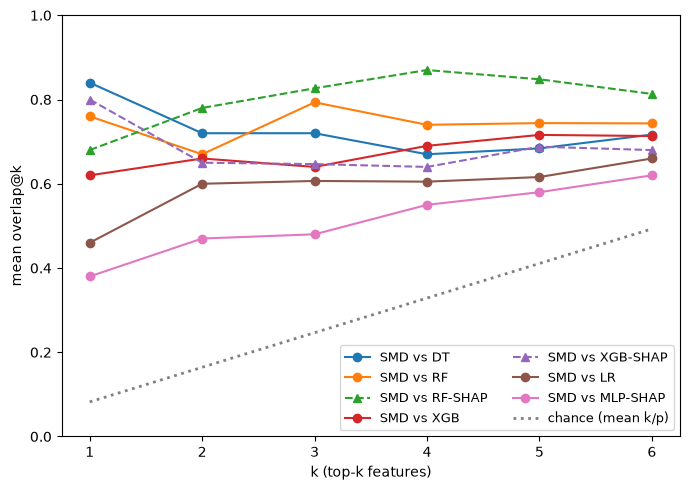

In [10]:
ks = range(1, 7)
fig, ax = plt.subplots(figsize=(7, 5))
for model, g in curves.groupby("model", sort=False):
    style = "-o" if model in PRIMARY else "--^"
    ax.plot(ks, g[list(ks)].mean(), style, label=f"SMD vs {model}")
chance = [np.mean([k / len(num + cat) for _, num, cat in DATASETS.values()]) for k in ks]
ax.plot(ks, chance, ":", color="grey", lw=2, label="chance (mean k/p)")
ax.set(xlabel="k (top-k features)", ylabel="mean overlap@k", ylim=(0, 1), xticks=list(ks))
ax.legend(fontsize=9, ncol=2, loc="lower right")
fig.tight_layout()
fig.savefig(RESULTS / "agreement_at_k.png", dpi=150)
plt.show()